<a href="https://colab.research.google.com/github/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA/blob/main/notebooks/30_expansion/31_expansion_eva_vs_mapbiomas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 31 · Palma de aceite: EVA frente a MapBiomas

**Autor:** Daniel

**Pregunta (sección 11.2 de la ruta):** ¿la EVA y MapBiomas cuentan la misma historia de la palma de aceite en la Altillanura?

**Entradas:**
- EVA: `modulos/expansion/datos/eva/eva_altillanura_anual.csv` (Git), cultivo `PALMA DE ACEITE`, área sembrada y cosechada.
- MapBiomas Colombia, Colección 3: `modulos/expansion/datos/mapbiomas_crudos/` (Git), clase de nivel 2 "Palm oil".
- Panel común `datos/comunes/panel_municipio_anio.csv` (Git, cuaderno 60), solo para comprobar que la palma de las dos fuentes es la misma del panel. Se leen las tablas de origen porque el panel no trae el área cosechada de la EVA.

**Salidas:**
- `modulos/expansion/resultados/31_palma_eva_mapbiomas.csv`: una fila por municipio y año.
- `modulos/expansion/resultados/31_palma_resumen.csv`: Spearman y sesgo por grupo.
- `modulos/expansion/graficas/31_palma_eva_vs_mapbiomas.png`.

**Método:**
- Años comunes de las dos fuentes, desde el primer año en que la EVA reporta palma. Si un municipio reporta otros cultivos en la EVA un año pero no palma, su palma de la EVA es 0; si no reporta nada ese año, ese municipio-año queda fuera.
- Se comparan solo los municipio-año en que al menos una de las dos fuentes tiene palma; los que tienen 0 ha en las dos quedan fuera (el número exacto sale en el paso 2).
- **Spearman** (ρ): si las dos fuentes ordenan igual los municipio-año. Se calcula con todos los municipio-año, con la serie regional anual, con los cambios anuales de la serie regional y dentro de cada municipio.
- **Sesgo medio**: promedio de EVA − MapBiomas, en hectáreas, y sesgo relativo = suma de EVA − MapBiomas sobre la suma de MapBiomas, en %.

## Paso 1. Rutas y librerías
- En **Colab** clona el repo en `/content/Proyecto-ALTILLANURA`.
- En **local** toma como raíz la carpeta del repo (dos niveles arriba del cuaderno).
- `traer(ruta)` baja de DVC un archivo cuando hace falta.

In [1]:
import os, sys, re, glob, subprocess, warnings
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        subprocess.run(['git', 'clone', '-q', REPO, RAIZ], check=True)
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))

COMUNES = os.path.join(RAIZ, 'datos', 'comunes')
EXPANSION = os.path.join(RAIZ, 'modulos', 'expansion')
CRUDOS = os.path.join(EXPANSION, 'datos', 'mapbiomas_crudos')
RESULTADOS = os.path.join(EXPANSION, 'resultados')
GRAFICAS = os.path.join(EXPANSION, 'graficas')
os.makedirs(RESULTADOS, exist_ok=True)
os.makedirs(GRAFICAS, exist_ok=True)

def traer(ruta):
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)

def coma(valor, decimales=1):
    return f'{valor:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy import stats

print('Raíz del repo:', RAIZ)

Raíz del repo: c:\Users\mipip\Downloads\altillanura_proyecto_\altillanura_proyecto


## Paso 2. Palma en las dos fuentes

In [2]:
partes = []
for ruta in sorted(glob.glob(os.path.join(CRUDOS, '*.csv'))):
    mb = pd.read_csv(ruta, encoding='utf-8-sig')
    mb['Level 2'] = mb['Level 2'].fillna('').str.strip()
    mb = mb[mb['Level 2'] != '']
    largo = mb.melt(id_vars=['Level 1', 'Level 2'], var_name='anio', value_name='ha')
    largo['anio'] = largo['anio'].astype(int)
    largo['ha'] = pd.to_numeric(largo['ha'], errors='coerce').fillna(0.0)
    largo['mpio_cdpmp'] = re.search(r'(\d{5})_', os.path.basename(ruta)).group(1)
    partes.append(largo)
mb = pd.concat(partes, ignore_index=True)
assert mb['mpio_cdpmp'].nunique() == 7

nombres = (pd.read_csv(os.path.join(COMUNES, 'altillanura_municipios.csv'), dtype={'mpio_cdpmp': str})
           .set_index('mpio_cdpmp')['mpio_cnmbr'])

mb_palma = (mb[mb['Level 2'] == 'Palm oil'].groupby(['mpio_cdpmp', 'anio'])['ha'].sum()
            .rename('mapbiomas_ha'))

eva = pd.read_csv(os.path.join(EXPANSION, 'datos', 'eva', 'eva_altillanura_anual.csv'), encoding='utf-8-sig')
eva['mpio_cdpmp'] = eva['cod_mun'].astype(str).str.zfill(5)
reporta = eva.groupby(['mpio_cdpmp', 'anio']).size().rename('reporta')
palma = eva[eva['cultivo'] == 'PALMA DE ACEITE'].groupby(['mpio_cdpmp', 'anio'])[['area_sembrada_ha', 'area_cosechada_ha']].sum()
eva_palma = pd.concat([reporta, palma], axis=1)
eva_palma[['area_sembrada_ha', 'area_cosechada_ha']] = eva_palma[['area_sembrada_ha', 'area_cosechada_ha']].fillna(0.0)
eva_palma = eva_palma.rename(columns={'area_sembrada_ha': 'eva_sembrada_ha', 'area_cosechada_ha': 'eva_cosechada_ha'}).drop(columns='reporta')

anios_eva = palma.index.get_level_values('anio')
anios_mb = mb_palma.index.get_level_values('anio')
ANIO_0, ANIO_1 = max(anios_eva.min(), anios_mb.min()), min(anios_eva.max(), anios_mb.max())
tabla = eva_palma.join(mb_palma, how='inner').reset_index()
tabla = tabla[tabla['anio'].between(ANIO_0, ANIO_1)]
tabla['municipio'] = tabla['mpio_cdpmp'].map(nombres)
tabla['dif_sembrada_ha'] = tabla['eva_sembrada_ha'] - tabla['mapbiomas_ha']
con_palma = tabla[(tabla['eva_sembrada_ha'] > 0) | (tabla['mapbiomas_ha'] > 0)].copy()

tabla.round(2).to_csv(os.path.join(RESULTADOS, '31_palma_eva_mapbiomas.csv'), index=False)
N_USADOS, N_TOTAL = len(con_palma), len(tabla)
print(f'Años comunes: {ANIO_0}–{ANIO_1} | municipio-año con palma en alguna fuente: {N_USADOS} de {N_TOTAL} '
      f'(quedan fuera {N_TOTAL - N_USADOS} con 0 ha en las dos fuentes)')

traer('datos/comunes/panel_municipio_anio.csv')
panel = pd.read_csv(os.path.join(COMUNES, 'panel_municipio_anio.csv'), dtype={'mpio_cdpmp': str})
cruce = tabla.merge(panel[['mpio_cdpmp', 'anio', 'eva_palma_ha', 'palma_mapbiomas_ha']], on=['mpio_cdpmp', 'anio'], how='left')
DIF_PANEL = max((cruce['eva_sembrada_ha'] - cruce['eva_palma_ha']).abs().max(), (cruce['mapbiomas_ha'] - cruce['palma_mapbiomas_ha']).abs().max())
print(f'Comprobación con el panel común: diferencia máxima {DIF_PANEL:.3f} ha '
      f'({"coinciden" if DIF_PANEL < 0.01 else "NO coinciden, revisar el cuaderno 60"})')
print(f'\nPalma en {ANIO_1} (ha):')
print(tabla[tabla['anio'] == ANIO_1].set_index('municipio')[['eva_sembrada_ha', 'mapbiomas_ha']].round(0).to_string())

Años comunes: 2007–2024 | municipio-año con palma en alguna fuente: 97 de 126 (quedan fuera 29 con 0 ha en las dos fuentes)
Comprobación con el panel común: diferencia máxima 0.000 ha (coinciden)

Palma en 2024 (ha):
                eva_sembrada_ha  mapbiomas_ha
municipio                                    
MAPIRIPÁN                9391.0       10465.0
PUERTO GAITÁN           29490.0       13514.0
PUERTO LÓPEZ             3291.0        2845.0
PUERTO CARREÑO              0.0           0.0
LA PRIMAVERA             6000.0        1024.0
SANTA ROSALÍA           10400.0        1996.0
CUMARIBO                    0.0           0.0


## Paso 3. Spearman y sesgo
Se compara el área sembrada de la EVA (la que mejor corresponde a una cobertura que se ve desde el satélite) y, como referencia, el área cosechada.

Dos cuidados al leer los resultados:
- Las dos series regionales crecen con el tiempo, así que un ρ alto en niveles puede venir sobre todo de esa tendencia común. Por eso también se calcula ρ con los **cambios anuales** de la serie regional (cada año menos el anterior).
- Los valores p de Spearman suponen observaciones independientes. Los años de un mismo municipio no lo son, así que los valores p son solo orientativos y exageran la evidencia.

In [3]:
def comparar(grupo, etiqueta, columna='eva_sembrada_ha'):
    grupo = grupo.dropna(subset=[columna, 'mapbiomas_ha'])
    variables = len(grupo) >= 5 and grupo[columna].nunique() > 1 and grupo['mapbiomas_ha'].nunique() > 1
    rho, p = stats.spearmanr(grupo[columna], grupo['mapbiomas_ha']) if variables else (np.nan, np.nan)
    dif = grupo[columna] - grupo['mapbiomas_ha']
    total_mb = grupo['mapbiomas_ha'].sum()
    return {'grupo': etiqueta, 'medida_eva': columna.replace('_ha', ''), 'n': len(grupo), 'spearman': rho, 'p_valor': p,
            'sesgo_medio_ha': dif.mean(), 'sesgo_relativo_pct': dif.sum() / total_mb * 100 if total_mb > 0 else np.nan,
            'eva_media_ha': grupo[columna].mean(), 'mapbiomas_media_ha': grupo['mapbiomas_ha'].mean()}

regional = con_palma.groupby('anio')[['eva_sembrada_ha', 'eva_cosechada_ha', 'mapbiomas_ha']].sum().reset_index()
cambios = regional.set_index('anio').diff().dropna().reset_index()
filas = [comparar(con_palma, 'Municipio-año'), comparar(con_palma, 'Municipio-año', 'eva_cosechada_ha'),
         comparar(regional, 'Altillanura por año'), comparar(regional, 'Altillanura por año', 'eva_cosechada_ha'),
         comparar(cambios, 'Altillanura, cambio anual')]
MUNICIPIOS = sorted(con_palma['municipio'].unique())
for municipio, grupo in con_palma.groupby('municipio'):
    filas.append(comparar(grupo, municipio))
resumen = pd.DataFrame(filas)
resumen.round(4).to_csv(os.path.join(RESULTADOS, '31_palma_resumen.csv'), index=False)
print(resumen.round(3).to_string(index=False))

GLOBAL = resumen.iloc[0]
REGION = resumen.iloc[2]
CAMBIO = resumen.iloc[4]
POR_MUNICIPIO = resumen[resumen['grupo'].isin(MUNICIPIOS)]
CONTRARIOS = POR_MUNICIPIO[(POR_MUNICIPIO['sesgo_medio_ha'] < 0) | (POR_MUNICIPIO['spearman'] < 0)]

                    grupo    medida_eva  n  spearman  p_valor  sesgo_medio_ha  sesgo_relativo_pct  eva_media_ha  mapbiomas_media_ha
            Municipio-año  eva_sembrada 97     0.737    0.000        3622.914             106.323      7030.371            3407.458
            Municipio-año eva_cosechada 97     0.699    0.000        1876.635              55.074      5284.093            3407.458
      Altillanura por año  eva_sembrada 18     0.891    0.000       19523.479             106.323     37885.889           18362.410
      Altillanura por año eva_cosechada 18     0.988    0.000       10112.979              55.074     28475.389           18362.410
Altillanura, cambio anual  eva_sembrada 17    -0.039    0.881        1429.269              87.093      3070.353            1641.084
                 CUMARIBO  eva_sembrada  7       NaN      NaN         550.000                 NaN       550.000               0.000
             LA PRIMAVERA  eva_sembrada 18     0.867    0.000        2855.30

## Paso 4. Figura
A la izquierda, la palma de toda la Altillanura en las dos fuentes. A la derecha, cada municipio-año: los puntos sobre la diagonal son años en que la EVA reporta más palma que la que detecta MapBiomas.

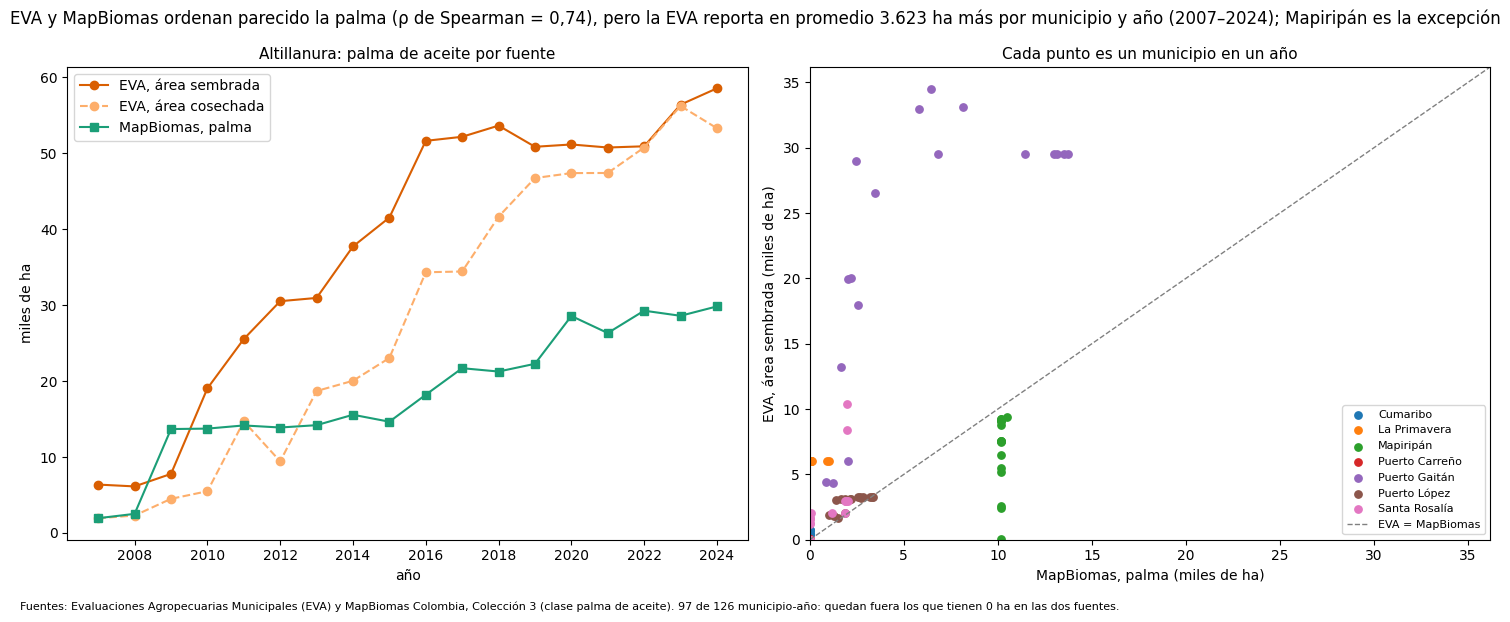

In [4]:
def coma0(valor):
    return coma(valor, 0)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].plot(regional['anio'], regional['eva_sembrada_ha'] / 1e3, marker='o', color='#d95f02', label='EVA, área sembrada')
axes[0].plot(regional['anio'], regional['eva_cosechada_ha'] / 1e3, marker='o', linestyle='--', color='#fdae6b', label='EVA, área cosechada')
axes[0].plot(regional['anio'], regional['mapbiomas_ha'] / 1e3, marker='s', color='#1b9e77', label='MapBiomas, palma')
axes[0].set_ylabel('miles de ha')
axes[0].set_xlabel('año')
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].set_title('Altillanura: palma de aceite por fuente', fontsize=11)
axes[0].legend()

paleta = plt.get_cmap('tab10').colors
for i, (municipio, grupo) in enumerate(con_palma.groupby('municipio')):
    axes[1].scatter(grupo['mapbiomas_ha'] / 1e3, grupo['eva_sembrada_ha'] / 1e3, s=28, color=paleta[i], label=municipio.title())
tope = max(con_palma['mapbiomas_ha'].max(), con_palma['eva_sembrada_ha'].max()) / 1e3 * 1.05
axes[1].plot([0, tope], [0, tope], color='grey', linestyle='--', linewidth=1, label='EVA = MapBiomas')
axes[1].set_xlim(0, tope)
axes[1].set_ylim(0, tope)
axes[1].set_xlabel('MapBiomas, palma (miles de ha)')
axes[1].set_ylabel('EVA, área sembrada (miles de ha)')
axes[1].set_title('Cada punto es un municipio en un año', fontsize=11)
axes[1].legend(fontsize=8)

sentido = 'más' if GLOBAL['sesgo_medio_ha'] > 0 else 'menos'
excepcion = (f'; {" y ".join(n.title() for n in CONTRARIOS["grupo"])} {"es la excepción" if len(CONTRARIOS) == 1 else "son las excepciones"}'
             if len(CONTRARIOS) else '')
fig.suptitle(f'EVA y MapBiomas ordenan parecido la palma (ρ de Spearman = {coma(GLOBAL["spearman"], 2)}), pero la EVA reporta en promedio '
             f'{coma0(abs(GLOBAL["sesgo_medio_ha"]))} ha {sentido} por municipio y año ({ANIO_0}–{ANIO_1}){excepcion}', fontsize=12)
fig.text(0.01, -0.02, f'Fuentes: Evaluaciones Agropecuarias Municipales (EVA) y MapBiomas Colombia, Colección 3 (clase palma de aceite). '
         f'{N_USADOS} de {N_TOTAL} municipio-año: quedan fuera los que tienen 0 ha en las dos fuentes.', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(GRAFICAS, '31_palma_eva_vs_mapbiomas.png'), dpi=150, bbox_inches='tight')
plt.show()

## Límites
- La EVA se construye con reportes municipales y consensos regionales; MapBiomas detecta la cobertura desde imágenes de 30 m. Una plantación joven puede estar sembrada en la EVA años antes de que MapBiomas la vea como palma.
- En la EVA hay cifras que se repiten varios años seguidos, lo que sugiere reportes que no se actualizaron.
- Con pocos municipios con palma y menos de 20 años comunes, los valores p de Spearman dentro de cada municipio son poco estables.
- Los valores p de Spearman suponen observaciones independientes, y los años de un mismo municipio no lo son: con todos los municipio-año y con la serie regional, el valor p exagera la evidencia.
- El ρ de la serie regional en niveles refleja sobre todo que las dos fuentes crecen juntas; el ρ de los cambios anuales dice si además coinciden año a año.
- El ρ conjunto puede esconder municipios donde las fuentes no coinciden; el resumen los nombra.

## Resumen para el informe

In [5]:
def rho(f):
    return coma(f.spearman, 2) if pd.notna(f.spearman) else '—'

print(f'Años comunes: {ANIO_0}–{ANIO_1}; se usan {N_USADOS} de {N_TOTAL} municipio-año '
      f'(quedan fuera {N_TOTAL - N_USADOS} con 0 ha de palma en las dos fuentes).')
print(f'La palma de las dos fuentes coincide con el panel común (diferencia máxima {DIF_PANEL:.3f} ha).')
print(f'Spearman municipio-año (EVA sembrada vs MapBiomas): {rho(GLOBAL)}; serie regional: {rho(REGION)}; '
      f'cambios anuales de la serie regional: {rho(CAMBIO)} (n = {int(CAMBIO["n"])}). '
      f'Los valores p ({GLOBAL["p_valor"]:.1g} y {REGION["p_valor"]:.1g}) son solo orientativos porque los años no son independientes.')
print(f'Sesgo medio EVA − MapBiomas: {coma0(GLOBAL["sesgo_medio_ha"])} ha por municipio y año '
      f'({coma(GLOBAL["sesgo_relativo_pct"])} % del área de MapBiomas).')
for _, f in CONTRARIOS.iterrows():
    print(f'Excepción: en {f.grupo.title()} ρ = {rho(f)} (p = {coma(f.p_valor, 2)}, n = {int(f.n)}) y el sesgo medio es {coma0(f.sesgo_medio_ha)} ha: '
          f'{"MapBiomas va por encima de la EVA" if f.sesgo_medio_ha < 0 else "la EVA va por encima de MapBiomas"}.')
for _, f in POR_MUNICIPIO.iterrows():
    print(f'  {f.grupo.title()}: ρ = {rho(f)}, sesgo medio {coma0(f.sesgo_medio_ha)} ha (n = {int(f.n)})')

Años comunes: 2007–2024; se usan 97 de 126 municipio-año (quedan fuera 29 con 0 ha de palma en las dos fuentes).
La palma de las dos fuentes coincide con el panel común (diferencia máxima 0.000 ha).
Spearman municipio-año (EVA sembrada vs MapBiomas): 0,74; serie regional: 0,89; cambios anuales de la serie regional: -0,04 (n = 17). Los valores p (8e-18 y 7e-07) son solo orientativos porque los años no son independientes.
Sesgo medio EVA − MapBiomas: 3.623 ha por municipio y año (106,3 % del área de MapBiomas).
Excepción: en Mapiripán ρ = -0,43 (p = 0,10, n = 16) y el sesgo medio es -3.473 ha: MapBiomas va por encima de la EVA.
  Cumaribo: ρ = —, sesgo medio 550 ha (n = 7)
  La Primavera: ρ = 0,87, sesgo medio 2.855 ha (n = 18)
  Mapiripán: ρ = -0,43, sesgo medio -3.473 ha (n = 16)
  Puerto Carreño: ρ = —, sesgo medio 35 ha (n = 2)
  Puerto Gaitán: ρ = 0,80, sesgo medio 17.128 ha (n = 18)
  Puerto López: ρ = 0,83, sesgo medio 686 ha (n = 18)
  Santa Rosalía: ρ = 0,85, sesgo medio 1.723 h